In [1]:
# ============================================================
# PHASE 3 — CELL 1
# Environment Check
# ============================================================

import sys
import torch
import onnxruntime as ort

print("=" * 70)
print("PHASE 3 — ENVIRONMENT CHECK")
print("=" * 70)

print("Python :", sys.executable)
print("Torch  :", torch.__version__)
print("CUDA   :", torch.version.cuda)
print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count :", torch.cuda.device_count())
    print("GPU      :", torch.cuda.get_device_name(0))
else:
    print("GPU      : NOT AVAILABLE")

print()
print("ONNX Runtime :", ort.__version__)
print("Providers    :", ort.get_available_providers())

print("=" * 70)

PHASE 3 — ENVIRONMENT CHECK
Python : c:\Users\User\AppData\Local\Programs\Python\Python311\python.exe
Torch  : 2.13.0+cu126
CUDA   : 12.6
CUDA available : True
GPU count : 1
GPU      : NVIDIA GeForce RTX 4050 Laptop GPU

ONNX Runtime : 1.27.0
Providers    : ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


In [2]:
# ============================================================
# PHASE 3 — CELL 2
# Imports
# ============================================================

import os
import cv2
import json
import gc
import shutil
import traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone

from tqdm.auto import tqdm

from insightface.app import FaceAnalysis
from skimage.transform import SimilarityTransform

In [3]:
# ============================================================
# PHASE 3 — CELL 3
# Production Configuration
# ============================================================

PROJECT_DIR = Path(
    r"C:\LipReadingSSL"
).resolve()

OUTPUT_DIR = (
    PROJECT_DIR / "output"
)

SUPPORTED_VIDEO_EXTENSIONS = {
    ".webm",
    ".mp4",
    ".avi",
    ".mov",
    ".mkv",
    ".mpg",
    ".mpeg",
}

IMAGE_SIZE = 256

GPU_ID = 0

DET_SIZE = (
    640,
    640
)

MIN_FACE_SCORE = 0.50

FORCE_RERUN = False

SAVE_ALIGNMENT_PREVIEW = True

SAVE_ORIGINAL_LANDMARK = True

SAVE_ALIGNED_LANDMARK = True

SAVE_TRANSFORM = True

SAVE_METADATA = True

# ถ้า True จะข้าม frame ที่ Phase 2 บอกว่าไม่มีหน้า
USE_FACE_DETECTED_FILTER = True

print("=" * 70)
print("PHASE 3 — PRODUCTION CONFIGURATION")
print("=" * 70)

print("Project       :", PROJECT_DIR)
print("Output        :", OUTPUT_DIR)
print("Image Size    :", IMAGE_SIZE)
print("GPU ID        :", GPU_ID)
print("Detection     :", MIN_FACE_SCORE)
print("Force Rerun   :", FORCE_RERUN)

print("=" * 70)

if not OUTPUT_DIR.exists():
    raise FileNotFoundError(
        f"Output directory not found:\n{OUTPUT_DIR}"
    )

PHASE 3 — PRODUCTION CONFIGURATION
Project       : C:\LipReadingSSL
Output        : C:\LipReadingSSL\output
Image Size    : 256
GPU ID        : 0
Detection     : 0.5
Force Rerun   : False


In [4]:
# ============================================================
# PHASE 3 — CELL 4
# Helper Functions
# ============================================================

def utc_now_iso():

    return datetime.now(
        timezone.utc
    ).isoformat()


def get_video_id(
    video_path
):

    return Path(
        video_path
    ).stem


def get_video_dir(
    video_path
):

    video_id = get_video_id(
        video_path
    )

    return (
        OUTPUT_DIR /
        video_id
    )


def get_phase3_paths(
    video_path
):

    out = get_video_dir(
        video_path
    )

    return {

        "root": out,

        "detection_csv":
            out / "detection.csv",

        "aligned_face":
            out / "aligned_face",

        "landmarks_original":
            out / "landmarks_original",

        "landmarks_aligned":
            out / "landmarks_aligned",

        "transform":
            out / "transform",

        "preview":
            out / "alignment_preview",

        "metadata":
            out / "alignment_metadata.csv",

        "state":
            out / "phase3_state.json",

        "skipped":
            out / "phase3_skipped_frames.csv",

    }


def read_json(
    path
):

    path = Path(path)

    if not path.exists():
        return {}

    try:

        with open(
            path,
            "r",
            encoding="utf-8"
        ) as f:

            return json.load(f)

    except Exception:

        return {}


def write_json(
    path,
    data
):

    path = Path(path)

    temp = path.with_suffix(
        ".tmp"
    )

    with open(
        temp,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            data,
            f,
            indent=2,
            ensure_ascii=False
        )

    temp.replace(
        path
    )

In [5]:
# ============================================================
# PHASE 3 — CELL 5
# Output Structure
# ============================================================

def create_output_structure(
    video_path
):

    paths = get_phase3_paths(
        video_path
    )

    for key in [

        "aligned_face",
        "landmarks_original",
        "landmarks_aligned",
        "transform",
        "preview",

    ]:

        paths[key].mkdir(
            parents=True,
            exist_ok=True
        )

    return paths


print(
    "Phase 3 output structure ready."
)

Phase 3 output structure ready.


In [6]:
# ============================================================
# PHASE 3 — CELL 6
# Load Phase 2 Detection CSV
# ============================================================

REQUIRED_COLUMNS = [
    "video_id",
    "frame_index",
    "timestamp",
    "face_detected",
]


def load_detection_csv(
    video_path
):

    paths = get_phase3_paths(
        video_path
    )

    csv_path = paths[
        "detection_csv"
    ]

    if not csv_path.exists():

        raise FileNotFoundError(
            f"Detection CSV not found:\n"
            f"{csv_path}"
        )

    df = pd.read_csv(
        csv_path
    )

    missing = [

        col

        for col in REQUIRED_COLUMNS

        if col not in df.columns

    ]

    if missing:

        raise ValueError(
            "Detection CSV missing columns: "
            + ", ".join(missing)
        )

    # --------------------------------------------------------
    # Normalize frame index
    # --------------------------------------------------------

    df["frame_index"] = pd.to_numeric(
        df["frame_index"],
        errors="coerce"
    )

    df = df[
        df["frame_index"].notna()
    ].copy()

    df["frame_index"] = (
        df["frame_index"]
        .astype(int)
    )

    # --------------------------------------------------------
    # Normalize face_detected
    # --------------------------------------------------------

    df["face_detected"] = (
        df["face_detected"]
        .astype(str)
        .str.lower()
        .isin([
            "true",
            "1",
            "yes"
        ])
    )

    df = df.sort_values(
        "frame_index"
    )

    df = df.drop_duplicates(
        subset=["frame_index"],
        keep="last"
    )

    return df


def get_target_frames(
    video_path
):

    df = load_detection_csv(
        video_path
    )

    if USE_FACE_DETECTED_FILTER:

        target = df[
            df["face_detected"] == True
        ].copy()

    else:

        target = df.copy()

    return target


print(
    "Detection CSV loader ready."
)

Detection CSV loader ready.


In [7]:
# ============================================================
# PHASE 3 — CELL 7
# InsightFace Initialization
# ============================================================

providers = [
    "CUDAExecutionProvider",
    "CPUExecutionProvider"
]

if (
    "CUDAExecutionProvider"
    not in ort.get_available_providers()
):

    print(
        "WARNING: CUDAExecutionProvider "
        "not available."
    )

    providers = [
        "CPUExecutionProvider"
    ]


app = FaceAnalysis(
    name="buffalo_l",
    providers=providers
)

ctx_id = (
    GPU_ID
    if "CUDAExecutionProvider"
    in providers
    else -1
)

app.prepare(
    ctx_id=ctx_id,
    det_size=DET_SIZE
)

print("=" * 70)
print("InsightFace Ready")
print("Providers :", providers)
print("Context   :", ctx_id)
print("=" * 70)

Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\User/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\User/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106 ['None', 3, 192, 192] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\User/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\User/.insightface\models\buffalo_l\genderage.onnx genderage ['None', 3, 96, 96] 0.0 1.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\User/.insightface\models\buffalo_l\w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127

In [8]:
# ============================================================
# PHASE 3 — CELL 8
# Face Alignment
# ============================================================

# ArcFace 5-point template
SRC = np.array([
    [38.2946, 51.6963],
    [73.5318, 51.5014],
    [56.0252, 71.7366],
    [41.5493, 92.3655],
    [70.7299, 92.2041],
], dtype=np.float32)


def estimate_transform(
    kps,
    image_size=256
):

    src = SRC.copy()

    src *= (
        image_size / 112.0
    )

    tform = SimilarityTransform()

    success = tform.estimate(
        kps.astype(np.float32),
        src
    )

    if not success:

        raise RuntimeError(
            "SimilarityTransform estimation failed."
        )

    return tform.params[:2].astype(
        np.float32
    )


def align_face(
    image,
    face
):

    if face.kps is None:

        raise RuntimeError(
            "Face 5-point landmarks unavailable."
        )

    M = estimate_transform(
        face.kps,
        IMAGE_SIZE
    )

    aligned = cv2.warpAffine(
        image,
        M,
        (
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    return aligned, M


def transform_landmarks(
    landmarks,
    M
):

    landmarks = np.asarray(
        landmarks,
        dtype=np.float32
    )

    ones = np.ones(
        (
            landmarks.shape[0],
            1
        ),
        dtype=np.float32
    )

    pts = np.concatenate(
        [
            landmarks,
            ones
        ],
        axis=1
    )

    aligned = (
        M @ pts.T
    ).T

    return aligned.astype(
        np.float32
    )


print(
    "Alignment functions ready."
)

Alignment functions ready.


In [9]:
# ============================================================
# PHASE 3 — CELL 9
# Preview
# ============================================================

def draw_landmarks(
    image,
    landmarks,
    radius=1
):

    canvas = image.copy()

    for x, y in landmarks:

        cv2.circle(
            canvas,
            (
                int(round(x)),
                int(round(y))
            ),
            radius,
            (0, 255, 0),
            -1
        )

    return canvas


def save_preview(
    paths,
    original,
    aligned,
    landmark_original,
    landmark_aligned
):

    original_drawn = draw_landmarks(
        original,
        landmark_original
    )

    aligned_drawn = draw_landmarks(
        aligned,
        landmark_aligned
    )

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(10, 5)
    )

    axes[0].imshow(
        cv2.cvtColor(
            original_drawn,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[0].set_title(
        "Original"
    )

    axes[0].axis(
        "off"
    )

    axes[1].imshow(
        cv2.cvtColor(
            aligned_drawn,
            cv2.COLOR_BGR2RGB
        )
    )

    axes[1].set_title(
        "Aligned"
    )

    axes[1].axis(
        "off"
    )

    plt.tight_layout()

    fig.savefig(
        paths["preview"] /
        "preview.jpg",
        dpi=200
    )

    plt.close(
        fig
    )

In [10]:
# ============================================================
# PHASE 3 — CELL 10
# Resume / Existing Output
# ============================================================

def existing_completed_frames(
    paths
):

    folder = paths[
        "aligned_face"
    ]

    frames = set()

    for path in folder.glob(
        "frame_*.jpg"
    ):

        try:

            index = int(
                path.stem.split(
                    "_"
                )[-1]
            )

            frames.add(
                index
            )

        except Exception:

            continue

    return frames


def clear_phase3_output(
    paths
):

    folders = [

        "aligned_face",
        "landmarks_original",
        "landmarks_aligned",
        "transform",
        "alignment_preview",

    ]

    for folder_name in folders:

        folder = (
            paths["root"] /
            folder_name
        )

        if folder.exists():

            shutil.rmtree(
                folder
            )

        folder.mkdir(
            parents=True,
            exist_ok=True
        )

    for file_name in [

        "alignment_metadata.csv",
        "phase3_state.json",
        "phase3_skipped_frames.csv",

    ]:

        path = (
            paths["root"] /
            file_name
        )

        if path.exists():

            path.unlink()

In [11]:
# ============================================================
# PHASE 3 — CELL 11
# Production Video Processor
# ============================================================

def process_video(
    video_path
):

    video_path = Path(
        video_path
    ).resolve()

    video_id = get_video_id(
        video_path
    )

    paths = create_output_structure(
        video_path
    )

    print()
    print("=" * 70)
    print(
        f"PROCESSING : {video_id}"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # Detection CSV
    # --------------------------------------------------------

    detection_df = load_detection_csv(
        video_path
    )

    target_df = get_target_frames(
        video_path
    )

    target_frames = set(
        target_df[
            "frame_index"
        ].tolist()
    )

    print(
        f"Detection rows       : "
        f"{len(detection_df)}"
    )

    print(
        f"Face detected frames : "
        f"{len(target_frames)}"
    )

    # --------------------------------------------------------
    # Existing output
    # --------------------------------------------------------

    completed = (
        existing_completed_frames(
            paths
        )
    )

    if FORCE_RERUN:

        completed = set()

        clear_phase3_output(
            paths
        )

    remaining = (
        target_frames -
        completed
    )

    print(
        f"Already aligned      : "
        f"{len(completed)}"
    )

    print(
        f"Remaining             : "
        f"{len(remaining)}"
    )

    if not remaining:

        print(
            "Nothing to process."
        )

        return {
            "video": video_id,
            "target_frames":
                len(target_frames),
            "existing":
                len(completed),
            "processed": 0,
            "failed": 0,
            "skipped": 0,
        }

    # --------------------------------------------------------
    # Open video
    # --------------------------------------------------------

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():

        raise RuntimeError(
            f"Cannot open video:\n"
            f"{video_path}"
        )

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    print(
        f"Video frames         : "
        f"{total_frames}"
    )

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    metadata = []

    skipped = []

    processed = 0

    failed = 0

    preview_saved = (
        (paths["preview"] /
         "preview.jpg").exists()
    )

    # --------------------------------------------------------
    # Sequential read
    # --------------------------------------------------------

    frame_index = 0

    progress = tqdm(
        total=len(remaining),
        desc=video_id,
        unit="frame"
    )

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        current_index = frame_index

        frame_index += 1

        # ----------------------------------------------------
        # Skip frames not selected by Phase 2
        # ----------------------------------------------------

        if current_index not in remaining:

            continue

        # ----------------------------------------------------
        # Invalid frame
        # ----------------------------------------------------

        if frame is None:

            skipped.append({
                "video_id":
                    video_id,

                "frame_index":
                    current_index,

                "reason":
                    "frame_read_failed",
            })

            progress.update(
                1
            )

            continue

        try:

            # ------------------------------------------------
            # InsightFace
            # ------------------------------------------------

            faces = app.get(
                frame
            )

            if not faces:

                skipped.append({

                    "video_id":
                        video_id,

                    "frame_index":
                        current_index,

                    "reason":
                        "insightface_no_face",

                })

                progress.update(
                    1
                )

                continue

            # ------------------------------------------------
            # Select best face
            # ------------------------------------------------

            face = max(
                faces,
                key=lambda x:
                    float(
                        x.det_score
                    )
            )

            score = float(
                face.det_score
            )

            if score < MIN_FACE_SCORE:

                skipped.append({

                    "video_id":
                        video_id,

                    "frame_index":
                        current_index,

                    "reason":
                        "low_face_score",

                    "score":
                        score,

                })

                progress.update(
                    1
                )

                continue

            # ------------------------------------------------
            # Alignment
            # ------------------------------------------------

            aligned, M = align_face(
                frame,
                face
            )

            # ------------------------------------------------
            # Original landmarks
            # ------------------------------------------------

            landmark_original = (
                face.landmark_2d_106
                .astype(np.float32)
            )

            # ------------------------------------------------
            # Aligned landmarks
            # ------------------------------------------------

            landmark_aligned = (
                transform_landmarks(
                    landmark_original,
                    M
                )
            )

            # ------------------------------------------------
            # File naming
            # ------------------------------------------------

            frame_name = (
                f"frame_{current_index:06d}"
            )

            # ------------------------------------------------
            # Save aligned face
            # ------------------------------------------------

            aligned_path = (
                paths["aligned_face"] /
                f"{frame_name}.jpg"
            )

            cv2.imwrite(
                str(aligned_path),
                aligned
            )

            # ------------------------------------------------
            # Save original landmarks
            # ------------------------------------------------

            if SAVE_ORIGINAL_LANDMARK:

                np.save(

                    paths[
                        "landmarks_original"
                    ] /
                    f"{frame_name}.npy",

                    landmark_original

                )

            # ------------------------------------------------
            # Save aligned landmarks
            # ------------------------------------------------

            if SAVE_ALIGNED_LANDMARK:

                np.save(

                    paths[
                        "landmarks_aligned"
                    ] /
                    f"{frame_name}.npy",

                    landmark_aligned

                )

            # ------------------------------------------------
            # Save transform
            # ------------------------------------------------

            if SAVE_TRANSFORM:

                np.save(

                    paths[
                        "transform"
                    ] /
                    f"{frame_name}.npy",

                    M

                )

            # ------------------------------------------------
            # Metadata
            # ------------------------------------------------

            row = {

                "video_id":
                    video_id,

                "frame_index":
                    current_index,

                "timestamp":
                    (
                        current_index /
                        max(
                            1,
                            cap.get(
                                cv2.CAP_PROP_FPS
                            )
                        )
                    ),

                "face_score":
                    score,

                "bbox_x1":
                    float(
                        face.bbox[0]
                    ),

                "bbox_y1":
                    float(
                        face.bbox[1]
                    ),

                "bbox_x2":
                    float(
                        face.bbox[2]
                    ),

                "bbox_y2":
                    float(
                        face.bbox[3]
                    ),

                "status":
                    "ALIGNED",

            }

            metadata.append(
                row
            )

            processed += 1

            # ------------------------------------------------
            # Preview
            # ------------------------------------------------

            if (
                SAVE_ALIGNMENT_PREVIEW
                and not preview_saved
            ):

                save_preview(

                    paths,

                    frame,

                    aligned,

                    landmark_original,

                    landmark_aligned

                )

                preview_saved = True

            progress.update(
                1
            )

        except Exception as e:

            failed += 1

            skipped.append({

                "video_id":
                    video_id,

                "frame_index":
                    current_index,

                "reason":
                    f"{type(e).__name__}:{e}",

            })

            progress.update(
                1
            )

    progress.close()

    cap.release()

    # --------------------------------------------------------
    # Save metadata
    # --------------------------------------------------------

    metadata_df = pd.DataFrame(
        metadata
    )

    if SAVE_METADATA:

        metadata_df.to_csv(

            paths["metadata"],

            index=False,

            encoding="utf-8-sig"

        )

    # --------------------------------------------------------
    # Save skipped frames
    # --------------------------------------------------------

    skipped_df = pd.DataFrame(
        skipped
    )

    if not skipped_df.empty:

        skipped_df.to_csv(

            paths["skipped"],

            index=False,

            encoding="utf-8-sig"

        )

    # --------------------------------------------------------
    # State
    # --------------------------------------------------------

    state = {

        "video_id":
            video_id,

        "video_path":
            str(video_path),

        "target_frames":
            len(target_frames),

        "processed":
            processed,

        "failed":
            failed,

        "skipped":
            len(skipped),

        "completed_at":
            utc_now_iso(),

    }

    write_json(
        paths["state"],
        state
    )

    print()
    print(
        f"Processed : {processed}"
    )

    print(
        f"Skipped   : {len(skipped)}"
    )

    print(
        f"Failed    : {failed}"
    )

    return {

        "video":
            video_id,

        "target_frames":
            len(target_frames),

        "existing":
            len(completed),

        "processed":
            processed,

        "failed":
            failed,

        "skipped":
            len(skipped),

    }

In [12]:
# ============================================================
# PHASE 3 — CELL 12
# Output Validation
# ============================================================

def validate_video(
    video_path
):

    video_path = Path(
        video_path
    ).resolve()

    video_id = get_video_id(
        video_path
    )

    paths = get_phase3_paths(
        video_path
    )

    target_df = get_target_frames(
        video_path
    )

    target_frames = set(
        target_df[
            "frame_index"
        ].tolist()
    )

    aligned = {

        int(
            p.stem.split("_")[-1]
        )

        for p
        in paths[
            "aligned_face"
        ].glob("frame_*.jpg")

    }

    original_lm = {

        int(
            p.stem.split("_")[-1]
        )

        for p
        in paths[
            "landmarks_original"
        ].glob("frame_*.npy")

    }

    aligned_lm = {

        int(
            p.stem.split("_")[-1]
        )

        for p
        in paths[
            "landmarks_aligned"
        ].glob("frame_*.npy")

    }

    transform = {

        int(
            p.stem.split("_")[-1]
        )

        for p
        in paths[
            "transform"
        ].glob("frame_*.npy")

    }

    complete_frames = (
        aligned
        & original_lm
        & aligned_lm
        & transform
    )

    missing_output = (
        target_frames -
        complete_frames
    )

    print()
    print("=" * 70)
    print(
        f"VALIDATION : {video_id}"
    )
    print("=" * 70)

    print(
        "Target frames       :",
        len(target_frames)
    )

    print(
        "Aligned faces       :",
        len(aligned)
    )

    print(
        "Original landmarks  :",
        len(original_lm)
    )

    print(
        "Aligned landmarks   :",
        len(aligned_lm)
    )

    print(
        "Transform matrices  :",
        len(transform)
    )

    print(
        "Complete outputs    :",
        len(complete_frames)
    )

    print(
        "Missing outputs     :",
        len(missing_output)
    )

    if missing_output:

        print(
            "Missing sample     :",
            sorted(
                missing_output
            )[:20]
        )

    else:

        print(
            "✅ Validation PASS"
        )

    return {

        "video":
            video_id,

        "target":
            len(target_frames),

        "aligned":
            len(aligned),

        "original_landmark":
            len(original_lm),

        "aligned_landmark":
            len(aligned_lm),

        "transform":
            len(transform),

        "complete":
            len(complete_frames),

        "missing":
            len(missing_output),

        "valid":
            len(missing_output) == 0,

    }

In [13]:
# ============================================================
# PHASE 3 — CELL 13
# Discover Source Videos
# ============================================================

def discover_videos():

    videos = []

    raw_dir = (
        PROJECT_DIR /
        "dataset" /
        "raw_videos"
    )

    if not raw_dir.exists():

        raise FileNotFoundError(
            f"Raw video directory not found:\n"
            f"{raw_dir}"
        )

    for path in raw_dir.iterdir():

        if not path.is_file():
            continue

        if (
            path.suffix.lower()
            not in SUPPORTED_VIDEO_EXTENSIONS
        ):
            continue

        videos.append(
            path.resolve()
        )

    videos.sort(
        key=lambda p:
            p.name.lower()
    )

    return videos


VIDEOS = discover_videos()

print(
    f"Found {len(VIDEOS)} videos"
)

for video in VIDEOS:

    print(
        " -",
        video.name
    )

Found 3 videos
 - video001.webm
 - video002.webm
 - video003.webm


In [14]:
# ============================================================
# PHASE 3 — CELL 14
# Production Batch Runner
# ============================================================

BATCH_RESULTS = []

print()
print("=" * 70)
print("PHASE 3 — BATCH PROCESSING")
print("=" * 70)

for index, video_path in enumerate(
    VIDEOS,
    start=1
):

    video_id = get_video_id(
        video_path
    )

    print()
    print(
        f"[{index}/{len(VIDEOS)}] "
        f"{video_id}"
    )

    try:

        result = process_video(
            video_path
        )

        validation = validate_video(
            video_path
        )

        result.update(
            validation
        )

        BATCH_RESULTS.append(
            result
        )

    except Exception as e:

        print()
        print(
            f"❌ FAILED: {video_id}"
        )

        print(
            f"{type(e).__name__}: {e}"
        )

        traceback.print_exc()

        BATCH_RESULTS.append({

            "video":
                video_id,

            "valid":
                False,

            "error":
                f"{type(e).__name__}: {e}",

        })

    finally:

        try:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        except Exception:
            pass

        gc.collect()


PHASE 3 — BATCH PROCESSING

[1/3] video001

PROCESSING : video001
Detection rows       : 43725
Face detected frames : 42267
Already aligned      : 0
Remaining             : 42267
Video frames         : 43726


video001:   0%|          | 0/42267 [00:00<?, ?frame/s]


Processed : 41058
Skipped   : 1209
Failed    : 0

VALIDATION : video001
Target frames       : 42267
Aligned faces       : 41058
Original landmarks  : 41058
Aligned landmarks   : 41058
Transform matrices  : 41058
Complete outputs    : 41058
Missing outputs     : 1209
Missing sample     : [955, 1257, 1273, 1680, 4500, 4501, 4502, 4503, 4504, 4505, 4506, 4507, 4508, 4509, 4510, 4511, 4512, 4513, 4514, 4515]

[2/3] video002

PROCESSING : video002
Detection rows       : 39500
Face detected frames : 35613
Already aligned      : 0
Remaining             : 35613
Video frames         : 39501


video002:   0%|          | 0/35613 [00:00<?, ?frame/s]


Processed : 34794
Skipped   : 819
Failed    : 0

VALIDATION : video002
Target frames       : 35613
Aligned faces       : 34794
Original landmarks  : 34794
Aligned landmarks   : 34794
Transform matrices  : 34794
Complete outputs    : 34794
Missing outputs     : 819
Missing sample     : [1120, 1189, 1196, 1199, 1200, 1205, 1206, 1207, 1208, 1209, 1210, 1211, 1212, 1213, 1214, 1216, 1217, 1218, 1219, 5245]

[3/3] video003

PROCESSING : video003
Detection rows       : 42624
Face detected frames : 30422
Already aligned      : 0
Remaining             : 30422
Video frames         : 42625


video003:   0%|          | 0/30422 [00:00<?, ?frame/s]


Processed : 28276
Skipped   : 2146
Failed    : 0

VALIDATION : video003
Target frames       : 30422
Aligned faces       : 28276
Original landmarks  : 28276
Aligned landmarks   : 28276
Transform matrices  : 28276
Complete outputs    : 28276
Missing outputs     : 2146
Missing sample     : [1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 2039, 2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047, 2048]


In [15]:
# ============================================================
# PHASE 3 — CELL 15
# Batch Summary
# ============================================================

SUMMARY_DF = pd.DataFrame(
    BATCH_RESULTS
)

print()
print("=" * 70)
print("PHASE 3 — BATCH SUMMARY")
print("=" * 70)

if SUMMARY_DF.empty:

    print(
        "No results."
    )

else:

    columns = [

        "video",
        "target",
        "aligned",
        "original_landmark",
        "aligned_landmark",
        "transform",
        "complete",
        "missing",
        "valid",

    ]

    available = [

        col

        for col in columns

        if col in SUMMARY_DF.columns

    ]

    display(
        SUMMARY_DF[
            available
        ]
    )

print("=" * 70)


PHASE 3 — BATCH SUMMARY


,video,target,aligned,original_landmark,aligned_landmark,transform,complete,missing,valid
0,video001,42267,41058,41058,41058,41058,41058,1209,False
1,video002,35613,34794,34794,34794,34794,34794,819,False
2,video003,30422,28276,28276,28276,28276,28276,2146,False



PHASE 3 — FINAL RESULT
Total videos : 3
Passed       : 0
Failed       : 3

Total aligned faces : 104128
Total complete      : 104128
Total missing       : 4174


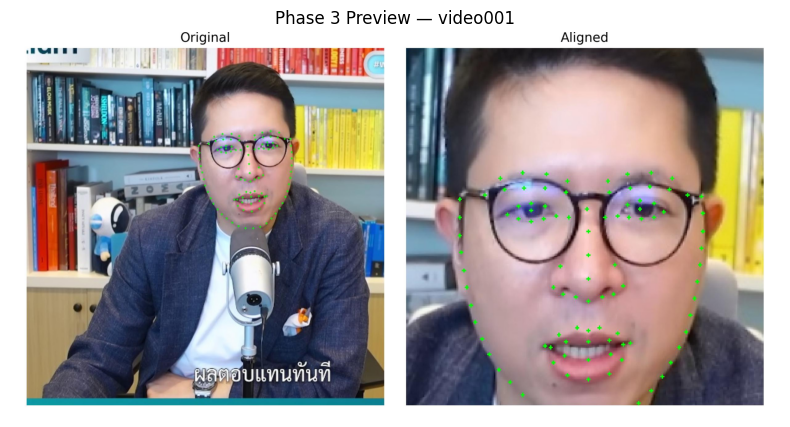

In [16]:
# ============================================================
# PHASE 3 — CELL 16
# Final Statistics
# ============================================================

print()
print("=" * 70)
print("PHASE 3 — FINAL RESULT")
print("=" * 70)

if not SUMMARY_DF.empty:

    total_videos = len(
        SUMMARY_DF
    )

    passed = int(
        SUMMARY_DF[
            "valid"
        ].fillna(False).sum()
    )

    print(
        "Total videos :",
        total_videos
    )

    print(
        "Passed       :",
        passed
    )

    print(
        "Failed       :",
        total_videos - passed
    )

    print()

    print(
        "Total aligned faces :",
        int(
            SUMMARY_DF[
                "aligned"
            ].fillna(0).sum()
        )
    )

    print(
        "Total complete      :",
        int(
            SUMMARY_DF[
                "complete"
            ].fillna(0).sum()
        )
    )

    print(
        "Total missing       :",
        int(
            SUMMARY_DF[
                "missing"
            ].fillna(0).sum()
        )
    )

print("=" * 70)

# ------------------------------------------------------------
# Random preview
# ------------------------------------------------------------

valid_videos = [

    v

    for v in VIDEOS

    if (
        get_phase3_paths(v)["preview"] /
        "preview.jpg"
    ).exists()

]

if valid_videos:

    preview_video = valid_videos[0]

    preview_path = (
        get_phase3_paths(
            preview_video
        )["preview"] /
        "preview.jpg"
    )

    img = cv2.imread(
        str(preview_path)
    )

    if img is not None:

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(
            figsize=(10, 5)
        )

        plt.imshow(
            img
        )

        plt.axis(
            "off"
        )

        plt.title(
            f"Phase 3 Preview — "
            f"{get_video_id(preview_video)}"
        )

        plt.show()